In [11]:

import pandas as pd

In [12]:
df = pd.read_csv("health_study_dataset.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [13]:
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]

df[columns].agg(["mean", "median", "min", "max"]).round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


 Beskrivande statistik

Jag har beräknat medelvärde, median, minsta och största värde för ålder, vikt, längd, systoliskt blodtryck och kolesterol.

Resultatet visar att medelåldern är 49,43 år och medelvikten är 73,41 kg. Det genomsnittliga systoliska blodtrycket är 149,18 mmHg och medelvärdet för kolesterol är 4,93 mmol/L.

Medelvärde och median ligger ganska nära varandra för dessa variabler. Det visar att det inte finns någon stor skillnad mellan de två måtten på centralvärde.

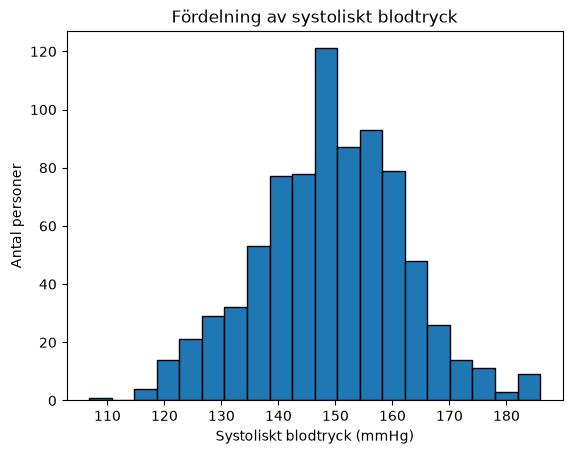

In [14]:
import matplotlib.pyplot as plt

plt.hist(df["systolic_bp"], bins=20, edgecolor="black")
plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal personer")
plt.show()

 Histogram över systoliskt blodtryck

Histogrammet visar hur det systoliska blodtrycket är fördelat bland deltagarna i studien.

De flesta blodtrycksvärden ligger ungefär mellan 140 och 160 mmHg. Det finns färre deltagare med mycket låga eller mycket höga värden.

Fördelningen har en tydlig koncentration kring mitten.

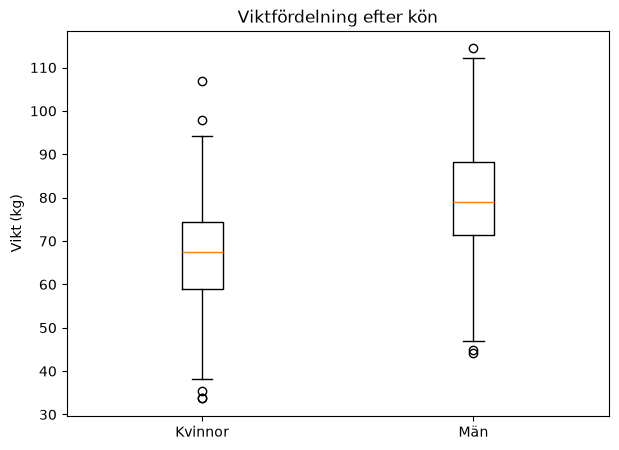

In [15]:
female = df[df["sex"] == "F"]["weight"].dropna()
male = df[df["sex"] == "M"]["weight"].dropna()

plt.figure(figsize=(7, 5))
plt.boxplot([female, male], tick_labels=["Kvinnor", "Män"])
plt.title("Viktfördelning efter kön")
plt.ylabel("Vikt (kg)")
plt.show()

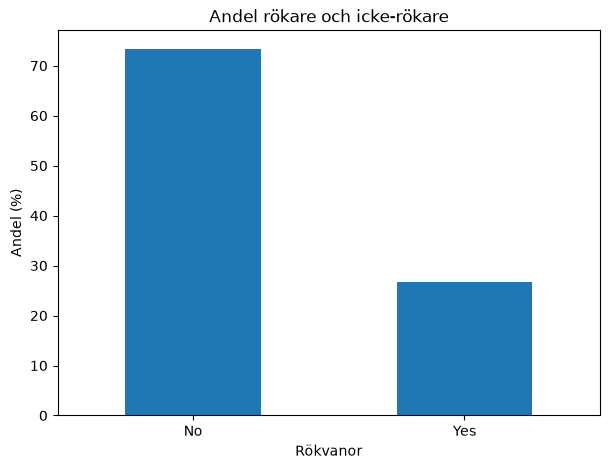

In [16]:
smoker_percent = df["smoker"].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 5))
smoker_percent.plot(kind="bar")

plt.title("Andel rökare och icke-rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.xticks(rotation=0)
plt.show()

 Tolkning av boxplot och stapeldiagram

Boxplot – Vikt efter kön**

Boxploten visar hur vikten är fördelad bland kvinnor och män i studien. Jag använder diagrammet för att jämföra medianen, spridningen och eventuella avvikande värden mellan grupperna.

**Stapeldiagram – Rökvanor**

Stapeldiagrammet visar andelen rökare och icke-rökare i procent. Diagrammet gör det lättare att jämföra hur vanliga de två grupperna är i studien.

In [17]:
import numpy as np

np.random.seed(42)

andel_sjuka = df["disease"].mean()

simulering = np.random.binomial(1, andel_sjuka, 1000)
andel_simulerad = simulering.mean()

print("Andel sjuka i datasetet:", round(andel_sjuka * 100, 2), "%")
print("Andel sjuka i simuleringen:", round(andel_simulerad * 100, 2), "%")

Andel sjuka i datasetet: 5.88 %
Andel sjuka i simuleringen: 5.6 %


 Simulering av sjukdomsförekomst

Andelen personer med sjukdomen i datasetet är 5,88 %.

Jag simulerade 1000 personer med NumPy och samma sannolikhet för sjukdom. I simuleringen blev andelen sjuka 5,6 %.

Skillnaden är 0,28 procentenheter. Resultaten ligger nära varandra, men är inte exakt lika eftersom simuleringen bygger på slumpmässiga utfall.

Jag använde `np.random.seed(42)` för att kunna upprepa simuleringen med samma resultat.

In [18]:
import numpy as np

bp = df["systolic_bp"].dropna().to_numpy()

# Metod 1: Normalapproximation
medel = np.mean(bp)
standardfel = np.std(bp, ddof=1) / np.sqrt(len(bp))

ci_normal = (
    medel - 1.96 * standardfel,
    medel + 1.96 * standardfel
)

# Metod 2: Bootstrap
rng = np.random.default_rng(42)

bootstrap_medel = [
    np.mean(rng.choice(bp, size=len(bp), replace=True))
    for _ in range(2000)
]

ci_bootstrap = np.percentile(bootstrap_medel, [2.5, 97.5])

print("Normalapproximation:", np.round(ci_normal, 2))
print("Bootstrap:", np.round(ci_bootstrap, 2))

Normalapproximation: [148.29 150.07]
Bootstrap: [148.29 150.06]


 Konfidensintervall för systoliskt blodtryck

Jag beräknade ett 95-procentigt konfidensintervall för medelvärdet av det systoliska blodtrycket med två olika metoder.

- Normalapproximation: 148,29–150,07 mmHg.
- Bootstrap: 148,29–150,06 mmHg.

Resultaten är nästan identiska, vilket visar att båda metoderna ger mycket liknande uppskattningar av osäkerheten kring medelvärdet.

Jag valde normalapproximation eftersom metoden använder medelvärdet och standardfelet. Jag använde även bootstrap för att jämföra med en metod som bygger på upprepad slumpmässig sampling från datasetet.

Ett 95-procentigt konfidensintervall innebär att metoden, vid upprepade stickprov, förväntas ge intervall som innehåller populationens verkliga medelvärde i ungefär 95 procent av fallen.

In [19]:
from scipy.stats import ttest_ind

rokare = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
icke_rokare = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

resultat = ttest_ind(
    rokare,
    icke_rokare,
    equal_var=False,
    alternative="greater"
)

print("Medelvärde rökare:", round(rokare.mean(), 2))
print("Medelvärde icke-rökare:", round(icke_rokare.mean(), 2))
print("p-värde:", round(resultat.pvalue, 5))

Medelvärde rökare: 149.52
Medelvärde icke-rökare: 149.05
p-värde: 0.32637


 Hypotesprövning – Rökare och blodtryck
Jag undersökte om rökare har högre systoliskt blodtryck än icke-rökare med hjälp av ett t-test
Medelvärdet för rökare var 149,52 mmHg och för icke-rökare 149,05 mmHg. Skillnaden var alltså liten.
P_värdet var ungefär 0,33, vilket är högre än 0,05. Därför kan jag inte dra slutsatsen att rökare har högre blodtryck i den här studien.






 Power-analys med simulering


In [20]:

import numpy as np
from scipy.stats import ttest_ind

rng = np.random.default_rng(42)
antal_simuleringar = 1000
antal_signifikanta = 0

for i in range(antal_simuleringar):
    grupp1 = rng.normal(150, 15, 100)
    grupp2 = rng.normal(155, 15, 100)

    resultat = ttest_ind(grupp2, grupp1, equal_var=False)

    if resultat.pvalue < 0.05:
        antal_signifikanta += 1

power = antal_signifikanta / antal_simuleringar

print("Power:", round(power * 100, 2), "%")


Power: 65.1 %



\Tolking av power-analys 
Jag gjorde 1000 simuleringar för att undersöka testets statistiska styrka (power). Jag använde två grupper med 100 personer i varje grupp och en verklig skillnad på 5 mmHg i medelblodtryck.\
\
Resultatet blev 65,1 %. Det betyder att testet upptäckte skillnaden i ungefär 65 % av simuleringarna.\
\
En power på 65,1 % är lägre än den vanliga målnivån på 80 %. Det betyder att testet ibland kan missa en verklig skillnad. Ett större antal deltagare skulle kunna öka testets power.


 Källor

- NumPy – Random sampling:
  https://numpy.org/doc/stable/reference/random/

- SciPy – t-test:
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

- SciPy – Bootstrap:
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html